In [1]:
%load_ext autoreload
%autoreload 2

In [31]:
import torch
from typing import Optional, Tuple
from dualwcfm.complete_trainer import (
    Strategy,
    BidirectionalStrategy,
    Trainer,
    ImplicitCFMLoss,
    ConditionalFlowMatching,
    TrainingConfig,
    FeedForwardConfig,
    Visualizer,
    Visualizer3D,
    VisualizerImage,
    VisualizeConfig,
)
from dualwcfm.distributions import (
    CouplingDistribution,
    RotatedShapeCoupling,
    Simple2DGaussianDistribution,
    RotatedDistribution,
    MoonDistribution,
    SphereDistribution,
    MarginalDistribution
)
from dualwcfm.models.unet import UNetModel
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class unet_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, t, x=None, inp3=None, *args, **kwargs):
        if inp3 is not None and x is not None:
            # print(x.shape, inp3.shape, torch.cat([x, inp3], dim=1).shape)
            return self.model(t, torch.cat([x, inp3], dim=1))
        if x is not None:
            # print(t.shape, x.shape)
            return self.model(t, x)
        else:
            return self.model(torch.zeros((32, 1), device=t.device), t)  # [:, :2]

class torch_wrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
        if inp3 is not None and inp2 is not None:
            return self.model(torch.cat([inp2, inp3, inp1], dim=1))  # [:, :2]
        if inp2 is not None:
            return self.model(torch.cat([inp2, inp1], dim=1))  # [:, :2]
        else:
            return self.model(inp1)  # [:, :2]
    # def forward(self, inp1, inp2=None, inp3=None, *args, **kwargs):
    #     if inp3 is not None and inp2 is not None:
    #         return self.model(inp1, torch.cat([inp2, inp3], dim=1))  # [:, :2]
    #     if inp2 is not None:
    #         return self.model(inp1, inp2)
    #     else:
    #         return self.model(inp1)  # [:, :2]

In [32]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

class ImageSampler:
    """Helper to turn a DataLoader into an infinite sampler."""

    def __init__(self, dataset, batch_size, device):
        self.loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=True)
        self.iterator = iter(self.loader)
        self.device = device

    def get_batch(self, n):
        try:
            batch, _ = next(self.iterator)
        except StopIteration:
            self.iterator = iter(self.loader)
            batch, _ = next(self.iterator)
        return batch[:n].to(self.device)

class FlipCoupling(CouplingDistribution):

    def __init__(self, dataset, batch_size=32, device: Optional[torch.device] = None):
        self.device = device if device is not None else torch.device("cpu")
        self.sampler = ImageSampler(dataset, batch_size, self.device)

    def coupling_sample(self, n: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.sampler.get_batch(n)
        y = torch.flip(x, dims=[1])
        return x, y

    def sample(self, n: int) -> torch.Tensor:
        raise NotImplementedError

    def sample_target(self, n: int) -> torch.Tensor:
        return self.sampler.get_batch(n)

    def sample_init(self, n: int) -> torch.Tensor:
        return torch.flip(self.sampler.get_batch(n), dims=[1])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_image = True

if use_image:
    tf = T.Compose([T.Resize(32), T.ToTensor(), T.Normalize((0.5,), (0.5,))])

    ds_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=tf)
    ds_fashion = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tf)

    coupling = FlipCoupling(dataset=ds_fashion, batch_size=32, device=device)

    new_coupling_dist = FlipCoupling(dataset=ds_mnist, batch_size=32, device=device)
    new_source = MarginalDistribution(new_coupling_dist.sample_init)
    new_target = MarginalDistribution(new_coupling_dist.sample_target)

else:
    def anticorrelate(n: int):
        source_samples = torch.randn(n, 2) * 0.5
        return source_samples, -source_samples

    coupling = FunctionalCouplingDistribution(anticorrelate)
    source, target = coupling.get_marginals()
    new_source = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([1.0, 1.0]))
    new_target = Simple2DGaussianDistribution(mean=torch.tensor([-5.0, -5.0]), std=torch.tensor([1.0, 1.0]))

In [33]:


# def anticorrelate(n: int):
#     source_samples = 2*torch.rand(n, 3) - 1
#     return source_samples, -source_samples

# coupling = FunctionalCouplingDistribution(anticorrelate)
# source, target = coupling.get_marginals()
# loc = 3.0
# new_source = SphereDistribution(mean=torch.tensor([loc, -loc, loc]), radius=0.25)
# new_target = SphereDistribution(mean=torch.tensor([-loc, loc, -loc]), radius=0.25)

In [34]:
class BidirectionalUnetStrategy(BidirectionalStrategy):
    # UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True).to(device)
    def _create_models(self, dim: int, hidden_size: int):
        wrapper = self.wrapper
        self.mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.f_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))
        self.g_dual = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1, stop_middle=True))

        self.forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.previous_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

        self.initial_mu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_nu_bridge = wrapper(UNetModel(dim=(1, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_forward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))
        self.initial_backward_model = wrapper(UNetModel(dim=(2, 32, 32), channel_mult=(1, 2, 3, 4), num_channels=32, num_res_blocks=1))

In [ ]:
training_config = TrainingConfig(device=device, iterations=50, marginal_epochs=20000, sigma=0.1)
small_training_config = TrainingConfig(device=device, iterations=200, batch_size=32, marginal_epochs=5, pretrain_epochs=5, dual_epochs=5, cfm_epochs=5)
model_config = FeedForwardConfig(dimension=3, hidden_size=32, dual_learning_rate=1e-4, flow_learning_rate=1e-3, mu_learning_rate=1e-3, nu_learning_rate=1e-3)

flow_matching = ConditionalFlowMatching()
# strategy = BidirectionalStrategy(torch_wrapper, model_config)
strategy = BidirectionalUnetStrategy(unet_wrapper, model_config)
# strategy = Strategy(unet_wrapper, model_config)
# visualizer = Visualizer(VisualizeConfig(show_each=10))
visualizer = VisualizerImage(VisualizeConfig(show_each=10), img_shape=(1, 32, 32))
# visualizer = Visualizer3D(VisualizeConfig(show_each=10))

trainer = Trainer(
    coupling, new_source, new_target,
    flow_matching, strategy, visualizer,
    small_training_config, device
)

Marginal Flow Matching:   0%|          | 0/5 [00:00<?, ?it/s]

torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])


Marginal Flow Matching:  40%|████      | 2/5 [00:00<00:00,  4.78it/s, Loss mu=0.556, Loss nu=0.638]

torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])


Marginal Flow Matching: 100%|██████████| 5/5 [00:00<00:00,  6.73it/s, Loss mu=0.569, Loss nu=0.52] 

torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])


Initial marginal flow models saved.
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torc

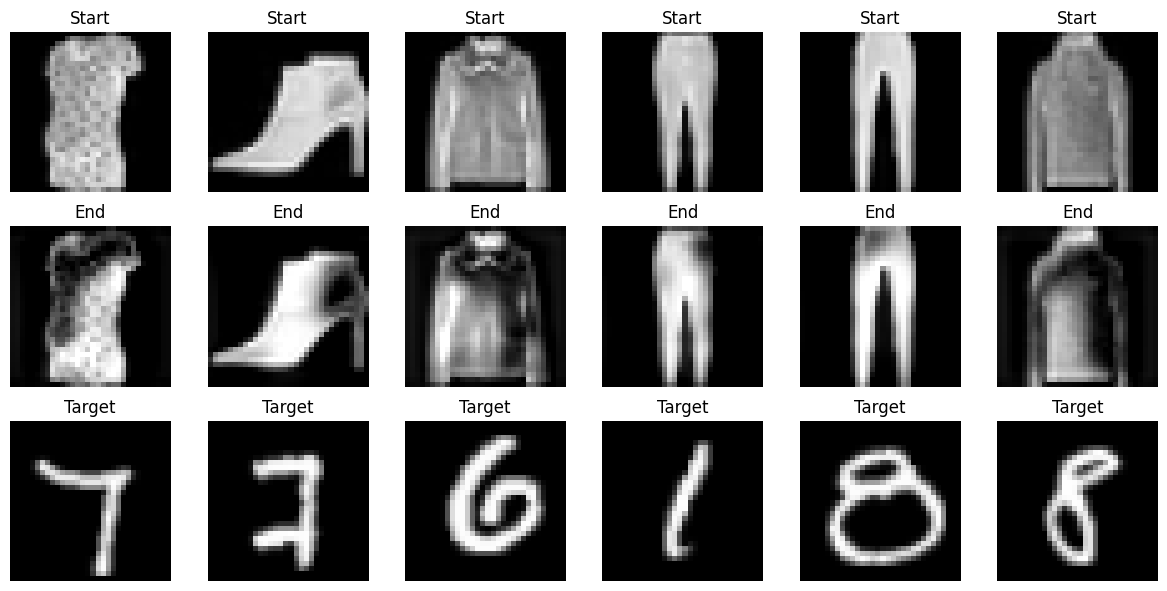

torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 32, 32])
torch.Size([32, 1]) torch.Size([32, 1, 3

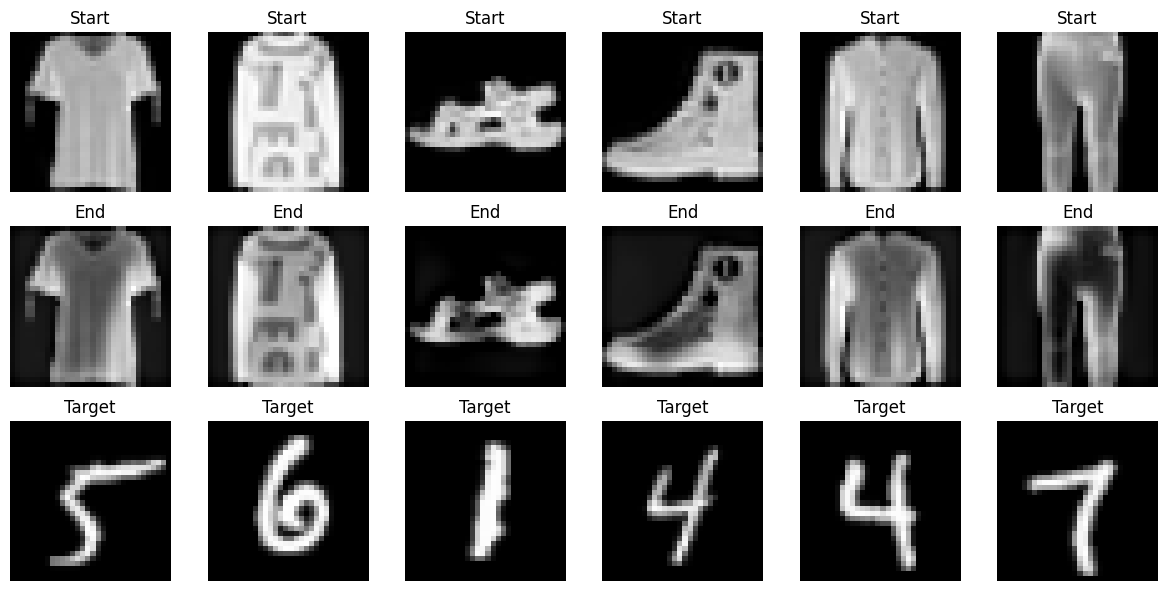

Pretraining bidirectional flows.


Pretraining:   0%|          | 0/5 [00:00<?, ?it/s, Pretrain Loss=0]

torch.Size([32, 1, 32, 32]) torch.Size([32, 1, 32, 32]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1, 32, 32]) torch.Size([32, 1, 32, 32]) torch.Size([32, 2, 32, 32])


Pretraining:  40%|████      | 2/5 [00:00<00:00, 17.11it/s, Pretrain Loss=0]

torch.Size([32, 1, 32, 32]) torch.Size([32, 1, 32, 32]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1, 32, 32]) torch.Size([32, 1, 32, 32]) torch.Size([32, 2, 32, 32])


Pretraining: 100%|██████████| 5/5 [00:00<00:00, 20.38it/s, Pretrain Loss=0]


... (5 outputs left out)

Pretraining:  60%|██████    | 3/5 [00:00<00:00, 25.35it/s, Pretrain Loss=0]

torch.Size([32, 1, 32, 32]) torch.Size([32, 1, 32, 32]) torch.Size([32, 2, 32, 32])


Pretraining: 100%|██████████| 5/5 [00:00<00:00, 24.65it/s, Pretrain Loss=0]


torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 32, 32])
torch.Size([32, 1]) torch.Size([32, 2, 3

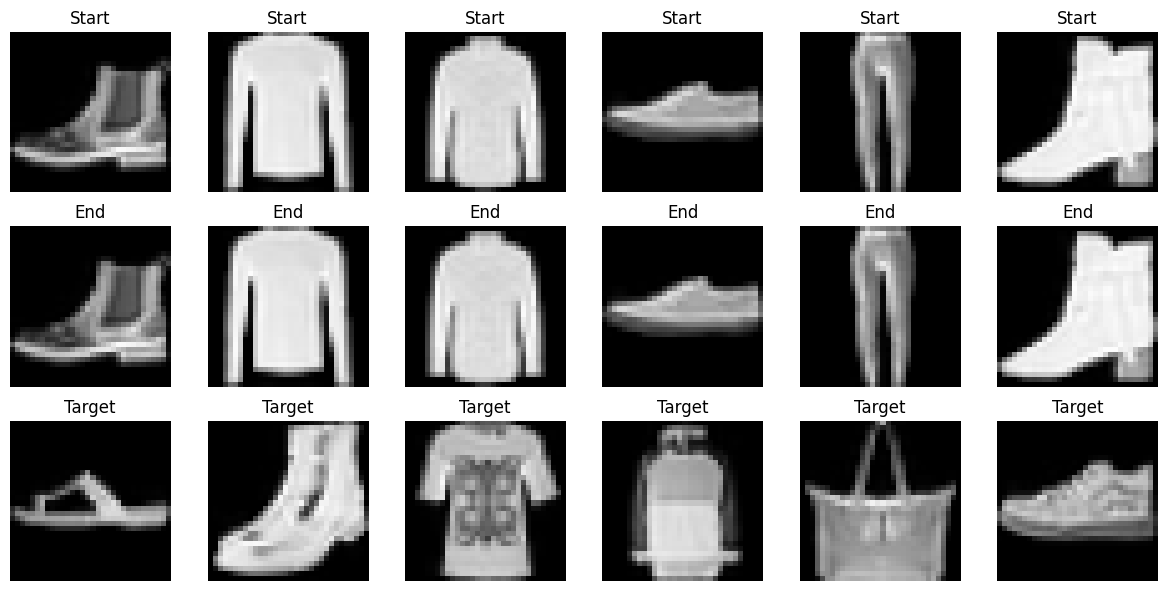

Iteration 1/200


Dual Training:   0%|          | 0/5 [00:00<?, ?it/s]


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [ ]:
trainer.train(retrain=True, save='experiments/image_flip_models/')

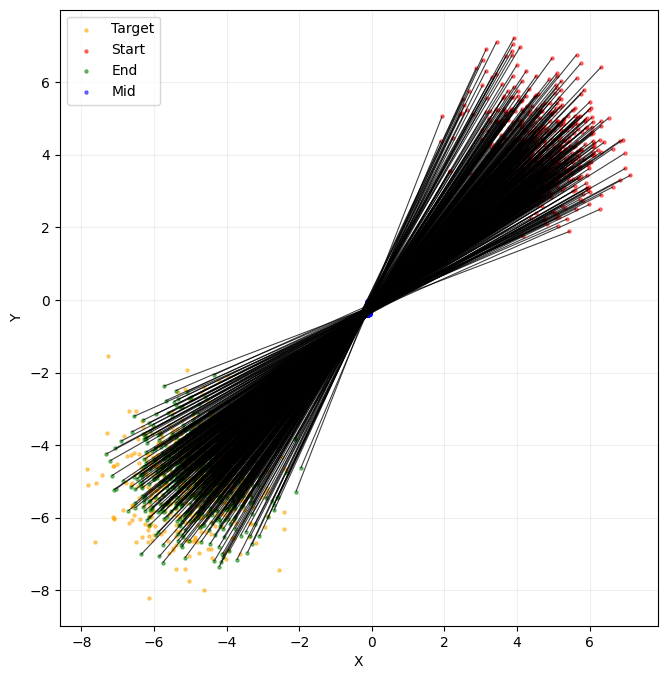

In [ ]:
import matplotlib.pyplot as plt
trainer.visualizer.display(10, trainer)
plt.show()

trainer.visualizer.display(11, trainer)
plt.show()